<a href="https://colab.research.google.com/github/shiv2314/AIMLMonth2023/blob/main/Copy_of_LSTMmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importing the required libraries
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
import numpy as np
import tensorflow as tf
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, RepeatVector, TimeDistributed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import keras

In [ ]:
# Mounting the drive and loading the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Reading the train data
data= pd.read_csv('/content/drive/MyDrive/DailyDelhiClimateTrain.csv')
print(data.shape)
data.head()

(1462, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [ ]:
# Reading the test data
data2= pd.read_csv('/content/drive/MyDrive/DailyDelhiClimateTest.csv')
print(data2.shape)
data2.head()

(114, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


In [ ]:
# Combining the Test and Train datasets
data = pd.concat([data, data2])
print(data.shape)
data.head()

(1576, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [ ]:
# Extracting date and meantemp from data
df = data[['date', 'meantemp']]
print(df.shape)
df.head()

(1576, 2)


,date,meantemp
0,2013-01-01,10.000000
1,2013-01-02,7.400000
2,2013-01-03,7.166667
3,2013-01-04,8.666667
4,2013-01-05,6.000000


In [ ]:
# Concise summary of a DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1576 entries, 0 to 113
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      1576 non-null   object 
 1   meantemp  1576 non-null   float64
dtypes: float64(1), object(1)
memory usage: 36.9+ KB


In [ ]:
df['date'].min(), df['date'].max()

('2013-01-01', '2017-04-24')

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df['date'], y=df['meantemp'], name='meantemp'))
fig.update_layout(showlegend=True, title='Time series graph of temperature')
fig.show()

In [ ]:
#TEST-TRAIN split
train = df.loc[df['date'] <= '2016-06-24']
test = df.loc[df['date'] > '2016-06-24']
train.shape, test.shape

((1271, 2), (305, 2))

Data Scaling

In [ ]:
scaler = StandardScaler()
scaler = scaler.fit(np.array(train['meantemp']).reshape(-1,1))

train['meantemp'] = scaler.transform(np.array(train['meantemp']).reshape(-1,1))
test['meantemp'] = scaler.transform(np.array(test['meantemp']).reshape(-1,1))

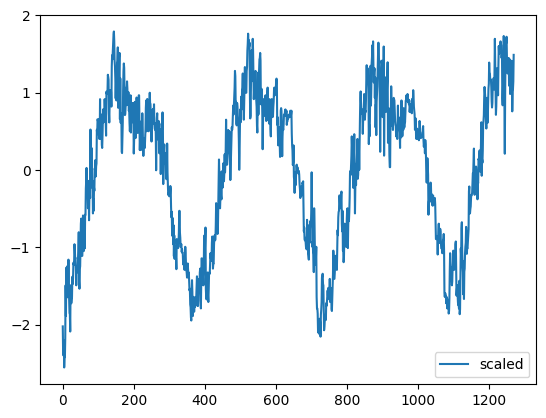

In [ ]:
# Visualize scaled data
plt.plot(train['meantemp'], label = 'scaled')
plt.legend()
plt.show()

In [ ]:
TIME_STEPS = 30

def create_sequences(X, y, time_steps=TIME_STEPS):
    X_out, y_out = [], []
    for i in range(len(X)-time_steps):
        X_out.append(X.iloc[i:(i+time_steps)].values)
        y_out.append(y.iloc[i+time_steps])

    return np.array(X_out), np.array(y_out)

X_train, y_train = create_sequences(train[['meantemp']], train['meantemp'])
X_test, y_test = create_sequences(test[['meantemp']], test['meantemp'])
print("Training input shape: ", X_train.shape)
print("Testing input shape: ", X_test.shape)

Training input shape:  (1241, 30, 1)
Testing input shape:  (275, 30, 1)


In [ ]:
# set seed to regenerate same sequence of random numbers.
np.random.seed(21)
tf.random.set_seed(21)

# **Build a model**

We are building LSTM Autoencoder model. The model will take input of shape (batch_size, sequence_length, num_features) and return output of the same shape. In this case, sequence_length is 30 and num_features is 1.

In [ ]:
#model = Sequential()
# model.add(LSTM(128, activation = 'tanh', input_shape=(X_train.shape[1], X_train.shape[2])))
# model.add(Dropout(rate=0.2))
# model.add(RepeatVector(X_train.shape[1]))
# model.add(LSTM(128, activation = 'tanh', return_sequences=True))
# model.add(Dropout(rate=0.2))
# model.add(TimeDistributed(Dense(X_train.shape[2])))

# model = tf.keras.models.Sequential([
#     tf.keras.layers.LSTM(32, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
#     tf.keras.layers.LSTM(16, activation='relu', return_sequences=False),
#     tf.keras.layers.RepeatVector(10),
#     tf.keras.layers.LSTM(16, activation='relu', return_sequences=True),
#     tf.keras.layers.LSTM(32, activation='relu', return_sequences=True),
#     tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))
# ])

sequence_length = 30
n_features = 4
model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    LSTM(32, activation='relu', return_sequences=False),
    RepeatVector(sequence_length),
    LSTM(32, activation='relu', return_sequences=True),
    LSTM(64, activation='relu', return_sequences=True),
    TimeDistributed(Dense(n_features))
])

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_8 (LSTM)               (None, 30, 64)            16896     
                                                                 
 lstm_9 (LSTM)               (None, 32)                12416     
                                                                 
 repeat_vector_2 (RepeatVec  (None, 30, 32)            0         
 tor)                                                            
                                                                 
 lstm_10 (LSTM)              (None, 30, 32)            8320      
                                                                 
 lstm_11 (LSTM)              (None, 30, 64)            24832     
                                                                 
 time_distributed_2 (TimeDi  (None, 30, 4)             260       
 stributed)                                           

In [ ]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100


InvalidArgumentError: ignored

In [ ]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

In [ ]:
# Mean Absolute Error loss
X_train_pred = model.predict(X_train)
X_train_pred.shape


In [ ]:
X_train.shape

In [ ]:
X_train_pred = X_train_pred.reshape((1241,30,1))
# train_mae_loss = np.mean((X_train_pred - X_train), axis=1)
train_mae_loss = np.mean(np.power(X_train_pred - X_train, 2), axis=1)
plt.hist(train_mae_loss)
plt.xlabel('Train MAE loss')
plt.ylabel('Number of Samples');

# Set reconstruction error threshold
threshold = np.max(train_mae_loss)

print('Reconstruction error threshold:',threshold)

In [ ]:
print('Shape of X_train:', np.shape(X_train))
print('Shape of X_train_pred:', np.shape(X_train_pred))

In [ ]:
X_test_pred = model.predict(X_test, verbose=1)
test_mae_loss = np.mean(np.abs(X_test_pred-X_test), axis=1)

plt.hist(test_mae_loss, bins=50)
plt.xlabel('Test MAE loss')
plt.ylabel('Number of samples')

In [ ]:
anomaly_df = pd.DataFrame(test[TIME_STEPS:])
anomaly_df['loss'] = test_mae_loss
anomaly_df['threshold'] = threshold
anomaly_df['anomaly'] = anomaly_df['loss'] > anomaly_df['threshold']

In [ ]:
anomaly_df.head()

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=anomaly_df['date'], y=anomaly_df['loss'], name='Test loss'))
fig.add_trace(go.Scatter(x=anomaly_df['date'], y=anomaly_df['threshold'], name='Threshold'))
fig.update_layout(showlegend=True, title='Test loss vs. Threshold')
fig.show()

In [ ]:
anomalies = anomaly_df.loc[anomaly_df['anomaly'] == True]
anomalies.head()

In [ ]:
anomalies.shape

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=anomaly_df['date'], y=anomaly_df['meantemp'], name='meantemp'))
fig.add_trace(go.Scatter(x=anomalies['date'], y=anomalies['meantemp'], mode='markers', name='Anomaly'))
fig.update_layout(showlegend=True, title='Detected anomalies')
fig.show()
